# 06 — Resultados y modelo seleccionado (§10–§11 del README)

| | |
|---|---|
| **Entrada** | Modelo candidato y umbral definidos en §9 (`notebooks/05_validation.ipynb`) |
| **Objetivo** | Evaluación final en el **test reservado** y decisión de modelo |
| **Salida** | Tabla de §10, matriz de confusión, curva PR y selección de §11 |

**Reglas:** el test **solo se toca aquí**, una vez, con el modelo y el umbral ya definidos en validación. Sin resultados inventados.

## 1. Enfoque

- Se usa el **test reservado** (8.236 filas, 11,27% `yes`), que no participó en CV ni en la elección del umbral.
- **Modelo candidato principal**: el mejor por PR-AUC en CV (§9).
- Se comparan, sobre el mismo test, el **baseline** (§7), el **modelo principal con umbral 0,5** y con el **umbral óptimo de F1** hallado en CV.
- **Métrica principal**: PR-AUC. Se reportan también precision, recall y F1 en cada punto de operación.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.linear_model import LogisticRegression

from src.models import build_candidate_models
from src.preprocessing import (
    RANDOM_STATE,
    clean_data,
    load_raw_data,
    split_features_target,
    train_test_split_data,
)

df = clean_data(load_raw_data())
X, y = split_features_target(df)
X_train, X_test, y_train, y_test = train_test_split_data(X, y)

UMBRAL_F1 = 0.1767441125685916  # definido en §9 (maximiza F1 out-of-fold)

def metricas(nombre, y_pred, y_proba, umbral):
    return {
        "Modelo": nombre,
        "Umbral": umbral,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
        "PR-AUC": average_precision_score(y_test, y_proba),
    }

filas = []
probas = {}

dummy = DummyClassifier(strategy="prior", random_state=RANDOM_STATE).fit(X_train, y_train)
filas.append(metricas("Dummy (prior)", dummy.predict(X_test), dummy.predict_proba(X_test)[:, 1], 0.5))

log = build_candidate_models()["Regresion logistica"].fit(X_train, y_train)
probas["Reg. logistica (§7)"] = log.predict_proba(X_test)[:, 1]
filas.append(metricas("Reg. logistica (§7)", log.predict(X_test), probas["Reg. logistica (§7)"], 0.5))

gb = build_candidate_models()["Gradient Boosting"].fit(X_train, y_train)
probas["GB (umbral 0.5)"] = gb.predict_proba(X_test)[:, 1]
probas["GB (umbral F1)"] = probas["GB (umbral 0.5)"]
filas.append(metricas("GB (umbral 0.5)", (probas["GB (umbral 0.5)"] >= 0.5).astype(int), probas["GB (umbral 0.5)"], 0.5))
filas.append(metricas(
    "GB (umbral F1, §9)",
    (probas["GB (umbral F1)"] >= UMBRAL_F1).astype(int),
    probas["GB (umbral F1)"],
    UMBRAL_F1,
))

resultados = pd.DataFrame(filas).set_index("Modelo")
resultados.round(3)

,Umbral,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Modelo,,,,,,,
Dummy (prior),0.500,0.887,0.000,0.000,0.000,0.500,0.113
Reg. logistica (§7),0.500,0.898,0.693,0.168,0.271,0.776,0.430
GB (umbral 0.5),0.500,0.897,0.640,0.197,0.301,0.808,0.453
"GB (umbral F1, §9)",0.177,0.873,0.451,0.605,0.517,0.808,0.453


## 2. Matriz de confusión y curva PR del modelo principal

La matriz de confusión traduce el punto de operación a llamadas: cuántos clientes que contratarían detectamos (TP) y cuántas llamadas inútiles hacemos (FP).

Matriz de confusion — Gradient Boosting, umbral F1:
          pred no  pred yes
real no      6626       682
real yes      367       561

Verdaderos positivos (recuperados)   : 561
Falsos negativos  (oportunidades perdidas): 367
Falsos positivos  (llamadas inutiles)    : 682
Verdaderos negativos                     : 6626


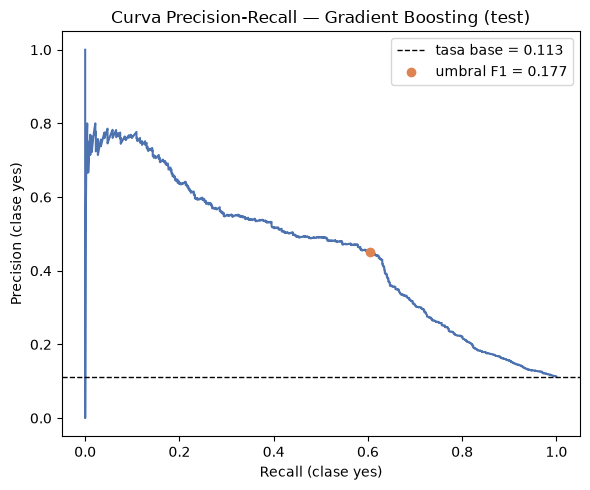

In [2]:
y_pred_f1 = (probas["GB (umbral F1)"] >= UMBRAL_F1).astype(int)

cm = confusion_matrix(y_test, y_pred_f1)
cm_df = pd.DataFrame(cm, index=["real no", "real yes"], columns=["pred no", "pred yes"])
print("Matriz de confusion — Gradient Boosting, umbral F1:")
print(cm_df.to_string())

tn, fp, fn, tp = cm.ravel()
print(f"\nVerdaderos positivos (recuperados)   : {tp}")
print(f"Falsos negativos  (oportunidades perdidas): {fn}")
print(f"Falsos positivos  (llamadas inutiles)    : {fp}")
print(f"Verdaderos negativos                     : {tn}")

prec, rec, _ = precision_recall_curve(y_test, probas["GB (umbral F1)"])
plt.figure(figsize=(6, 5))
plt.plot(rec, prec, color="#4C72B0")
plt.axhline(y_test.mean(), color="black", ls="--", lw=1, label=f"tasa base = {y_test.mean():.3f}")
plt.scatter([recall_score(y_test, y_pred_f1)], [precision_score(y_test, y_pred_f1)],
            color="#DD8452", zorder=5, label=f"umbral F1 = {UMBRAL_F1:.3f}")
plt.xlabel("Recall (clase yes)")
plt.ylabel("Precision (clase yes)")
plt.title("Curva Precision-Recall — Gradient Boosting (test)")
plt.legend()
plt.tight_layout()
plt.show()

## 3. Comparación final (§10)

Tabla de resultados para el README. Cada fila es un modelo/umbral evaluado una única vez sobre el test reservado.

In [3]:
print("Tabla comparativa final (test reservado, 8.236 filas):")
print(resultados.round(3).to_string())

print("\nDelta del umbral F1 vs umbral 0.5 en el GB:")
delta = (resultados.loc["GB (umbral F1, §9)"] - resultados.loc["GB (umbral 0.5)"]).round(3)
print(delta.to_string())

Tabla comparativa final (test reservado, 8.236 filas):
                     Umbral  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC
Modelo                                                                          
Dummy (prior)         0.500     0.887      0.000   0.000  0.000    0.500   0.113
Reg. logistica (§7)   0.500     0.898      0.693   0.168  0.271    0.776   0.430
GB (umbral 0.5)       0.500     0.897      0.640   0.197  0.301    0.808   0.453
GB (umbral F1, §9)    0.177     0.873      0.451   0.605  0.517    0.808   0.453

Delta del umbral F1 vs umbral 0.5 en el GB:
Umbral      -0.323
Accuracy    -0.024
Precision   -0.189
Recall       0.407
F1           0.215
ROC-AUC      0.000
PR-AUC       0.000


## 4. Variabilidad de la validación cruzada

La dispersión entre folds (PR-AUC std ≈ 0,014 en §9) indica que el desempeño es **estable**. La caída entre CV y test es esperable (más datos por fold en CV que una única partición).

In [4]:
print("Recordatorio de §9 (CV 5 folds sobre train):")
print("  Gradient Boosting  PR-AUC = 0.447 (std 0.014)")
print(f"  Gradient Boosting  PR-AUC en test = {resultados.loc['GB (umbral 0.5)', 'PR-AUC']:.3f}")
print(f"  Diferencia CV - test = {0.447 - resultados.loc['GB (umbral 0.5)', 'PR-AUC']:.3f} (esperable)")

Recordatorio de §9 (CV 5 folds sobre train):
  Gradient Boosting  PR-AUC = 0.447 (std 0.014)
  Gradient Boosting  PR-AUC en test = 0.453
  Diferencia CV - test = -0.006 (esperable)


## 5. Selección del modelo (§11)

**No se selecciona solo por la métrica más alta.** Criterios y evidencia:

| Criterio | Lectura |
|---|---|
| Métrica principal (PR-AUC) | GB 0,447 en CV (mejor) y estable (std 0,014) |
| Recall / F1 de `yes` | Random Forest logra más recall/F1 con `balanced`, pero PR-AUC algo menor |
| Interpretabilidad | Regresión logística es la más interpretable; GB/Forest son caja seminegra |
| Costo computacional | GB entrena en ~16 s/fold; logística en ~0,8 s |
| Uso previsto | Ranking de clientes: importa ordenar por probabilidad → ROC-AUC/PR-AUC |
| Disponibilidad real | Todas las features disponibles antes de llamar (§3) |

**Decisión:** el modelo principal es **Gradient Boosting**, con **umbral ajustado** según el objetivo (F1 para equilibrio; recall si se prioriza no perder clientes). La regresión logística queda como **modelo interpretable de referencia**.

## 6. Resumen para el README (§10–§11)

- Tabla de §10 con 4 filas: Dummy, logística, GB@0,5 y GB@umbral F1.
- Matriz de confusión del GB con umbral F1.
- Curva PR con la tasa base como referencia.
- Selección: **Gradient Boosting** (+ logística como referencia interpretable), con umbral documentado y trade-offs explícitos.

**Próximo paso:** §12 limitaciones y §13 conclusiones (redacción con evidencia ya generada).